# Phase 2 — ML Model Training: Decision Tree Classifier

This notebook implements the **Phase 2** experimental pipeline for the IoMT IDS thesis.  
Three training regimes are compared to quantify the benefit of multi-source dataset integration:

| Regime | Training data | Purpose |
|--------|--------------|---------|
| **B1** (CIC-only) | Only CICIoMT2024 rows | Baseline — large testbed, no DDoS gap |
| **B2** (IoMT-only) | Only IoMT-TrafficData rows | Baseline — hospital testbed, no DDoS class |
| **U** (Unified) | Full unified dataset | Proposed approach — multi-source integration |

**Models**: Decision Tree (baseline → tuned via `RandomizedSearchCV`)  
**Primary metric**: macro-F1 (equal weight to every class)  
**Protocol**: Tune on validation set → evaluate on test set **once** (§4.3 Lones, 2024)

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
%matplotlib inline
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300})
sns.set_style("whitegrid")

sys.path.insert(0, str(Path("..").resolve() / "src"))

from pipeline.training import (
    load_phase1_splits,
    prepare_regime,
    train_baseline_dt,
    tune_dt,
    evaluate_model,
    evaluate_cross_domain,
    build_eval_matrix,
    save_experiment,
    plot_confusion_matrix,
    plot_feature_importance,
    plot_regime_comparison,
    plot_per_class_f1,
    GLOBAL_CLASSES,
    FIGURES_DIR,
    RESULTS_DIR,
    REGIME_LABEL,
)

print("Imports OK")

Imports OK


## 1. Data Loading

Load the Phase 1 unified dataset (MQTT category scheme) — already split and scaled.

In [2]:
splits, feature_cols = load_phase1_splits()
print(f"\nFeature columns ({len(feature_cols)}):")
print(feature_cols)

  train: 5,608,073 rows × 65 cols
  val: 1,201,730 rows × 65 cols
  test: 1,201,731 rows × 65 cols
  Feature columns: 58

Feature columns (58):
['Window', 'Header_Length', 'Protocol_Type', 'TTL', 'HTTP', 'HTTPS', 'DNS', 'Telnet', 'SMTP', 'SSH', 'IRC', 'TCP', 'UDP', 'ICMP', 'IGMP', 'IAT', 'Tot_size', 'tcp_analysis_initial_rtt', 'tcp_connection_fin', 'tcp_connection_syn', 'tcp_flags_cwr', 'tcp_urgent_pointer', 'ip_frag_offset', 'eth_src_not_group', 'Rate', 'Srate', 'ack_count', 'syn_count', 'fin_count', 'rst_count', 'Bytes', 'Min_Length', 'Max_Length', 'Avg_Length', 'Std_Length', 'Number', 'Magnite', 'Radius', 'Covariance', 'Var_Ratio', 'Weight', 'Orig_Bytes', 'Resp_Bytes', 'Orig_Pkts', 'Resp_Pkts', 'Fwd_Pkts_Tot', 'Bwd_Pkts_Tot', 'Fwd_Pkts_Per_Sec', 'Bwd_Pkts_Per_Sec', 'Flow_Pkts_Per_Sec', 'Fwd_Header_Size', 'Bwd_Header_Size', 'Fwd_Pkts_Payload', 'Bwd_Pkts_Payload', 'Flow_Pkts_Payload', 'Fwd_IAT', 'Bwd_IAT', 'Flow_IAT']


  val: 1,201,730 rows × 65 cols


  test: 1,201,731 rows × 65 cols
  Feature columns: 58

Feature columns (58):
['Window', 'Header_Length', 'Protocol_Type', 'TTL', 'HTTP', 'HTTPS', 'DNS', 'Telnet', 'SMTP', 'SSH', 'IRC', 'TCP', 'UDP', 'ICMP', 'IGMP', 'IAT', 'Tot_size', 'tcp_analysis_initial_rtt', 'tcp_connection_fin', 'tcp_connection_syn', 'tcp_flags_cwr', 'tcp_urgent_pointer', 'ip_frag_offset', 'eth_src_not_group', 'Rate', 'Srate', 'ack_count', 'syn_count', 'fin_count', 'rst_count', 'Bytes', 'Min_Length', 'Max_Length', 'Avg_Length', 'Std_Length', 'Number', 'Magnite', 'Radius', 'Covariance', 'Var_Ratio', 'Weight', 'Orig_Bytes', 'Resp_Bytes', 'Orig_Pkts', 'Resp_Pkts', 'Fwd_Pkts_Tot', 'Bwd_Pkts_Tot', 'Fwd_Pkts_Per_Sec', 'Bwd_Pkts_Per_Sec', 'Flow_Pkts_Per_Sec', 'Fwd_Header_Size', 'Bwd_Header_Size', 'Fwd_Pkts_Payload', 'Bwd_Pkts_Payload', 'Flow_Pkts_Payload', 'Fwd_IAT', 'Bwd_IAT', 'Flow_IAT']


## 2. Regime Preparation

Prepare X/y arrays, LabelEncoder (global — all 6 classes), and balanced class weights for each regime.  
A **global** encoder is used so that integer labels are consistent across regimes, enabling fair cross-domain evaluation.

In [3]:
import gc


def _to_float32_mem(d):
    """Halve RAM for feature matrices; drop duplicate split DataFrames."""
    for k in ("X_train", "X_val", "X_test"):
        d[k] = d[k].astype(np.float32)
    del d["regime_splits"]
    gc.collect()
    return d


data_b1 = _to_float32_mem(prepare_regime(splits, feature_cols, regime="B1"))
data_b2 = _to_float32_mem(prepare_regime(splits, feature_cols, regime="B2"))
data_u = _to_float32_mem(prepare_regime(splits, feature_cols, regime="U"))

regimes = {"B1": data_b1, "B2": data_b2, "U": data_u}


────────────────────────────────────────────────────────────
Regime B1 — CIC-only
────────────────────────────────────────────────────────────
  train:  5,479,105 rows | classes ['Benign', 'DDoS', 'DoS', 'MQTT', 'Reconnaissance', 'Spoofing']
  val  :  1,174,093 rows | classes ['Benign', 'DDoS', 'DoS', 'MQTT', 'Reconnaissance', 'Spoofing']
  test :  1,174,095 rows | classes ['Benign', 'DDoS', 'DoS', 'MQTT', 'Reconnaissance', 'Spoofing']
  Balanced weights: {np.str_('Benign'): '56.39', np.str_('DDoS'): '0.24', np.str_('DoS'): '0.62', np.str_('MQTT'): '4.07', np.str_('Reconnaissance'): '99.23', np.str_('Spoofing'): '731.72'}

────────────────────────────────────────────────────────────
Regime B2 — IoMT-only
────────────────────────────────────────────────────────────
  train:    128,968 rows | classes ['Benign', 'DoS', 'MQTT', 'Reconnaissance', 'Spoofing']
  val  :     27,637 rows | classes ['Benign', 'DoS', 'MQTT', 'Reconnaissance', 'Spoofing']
  test :     27,636 rows | classes ['Benig

  Balanced weights: {np.str_('Benign'): '56.39', np.str_('DDoS'): '0.24', np.str_('DoS'): '0.62', np.str_('MQTT'): '4.07', np.str_('Reconnaissance'): '99.23', np.str_('Spoofing'): '731.72'}



────────────────────────────────────────────────────────────
Regime B2 — IoMT-only
────────────────────────────────────────────────────────────
  train:    128,968 rows | classes ['Benign', 'DoS', 'MQTT', 'Reconnaissance', 'Spoofing']
  val  :     27,637 rows | classes ['Benign', 'DoS', 'MQTT', 'Reconnaissance', 'Spoofing']
  test :     27,636 rows | classes ['Benign', 'DoS', 'MQTT', 'Reconnaissance', 'Spoofing']
  Balanced weights: {np.str_('Benign'): '1.22', np.str_('DoS'): '0.77', np.str_('MQTT'): '0.56', np.str_('Reconnaissance'): '1.12', np.str_('Spoofing'): '4.87'}

────────────────────────────────────────────────────────────
Regime U — Unified
────────────────────────────────────────────────────────────
  train:  5,608,073 rows | classes ['Benign', 'DDoS', 'DoS', 'MQTT', 'Reconnaissance', 'Spoofing']


  val  :  1,201,730 rows | classes ['Benign', 'DDoS', 'DoS', 'MQTT', 'Reconnaissance', 'Spoofing']
  test :  1,201,731 rows | classes ['Benign', 'DDoS', 'DoS', 'MQTT', 'Reconnaissance', 'Spoofing']


  Balanced weights: {np.str_('Benign'): '24.98', np.str_('DDoS'): '0.25', np.str_('DoS'): '0.62', np.str_('MQTT'): '3.46', np.str_('Reconnaissance'): '29.01', np.str_('Spoofing'): '142.87'}


## 3. Baseline Decision Trees

Train a Decision Tree with **default hyperparameters** and `class_weight='balanced'` for each regime.  
This establishes the lower-bound performance before tuning.

In [4]:
baseline_models = {}
for regime_key, data in regimes.items():
    print(f"\n{'='*60}")
    print(f"Training baseline DT — Regime {regime_key} ({REGIME_LABEL[regime_key]})")
    print(f"{'='*60}")
    dt = train_baseline_dt(data)
    baseline_models[regime_key] = dt

    # Quick validation-set check (NOT the final test evaluation)
    val_res = evaluate_model(
        dt, data["X_val"], data["y_val"],
        data["label_encoder"], f"{regime_key} val"
    )
print("\nBaseline training complete.")


Training baseline DT — Regime B1 (CIC-only)
  Baseline DT trained in 57.7s  (depth=154, leaves=772,915)
  [B1 val]  acc=0.8671  F1m=0.9131  F1w=0.8670

Training baseline DT — Regime B2 (IoMT-only)
  Baseline DT trained in 0.9s  (depth=15, leaves=56)
  [B2 val]  acc=0.9997  F1m=0.8332  F1w=0.9997

Training baseline DT — Regime U (Unified)
  Baseline DT trained in 66.9s  (depth=140, leaves=756,779)
  [U val]  acc=0.8700  F1m=0.9357  F1w=0.8699

Baseline training complete.


  Baseline DT trained in 57.7s  (depth=154, leaves=772,915)


  [B1 val]  acc=0.8671  F1m=0.9131  F1w=0.8670

Training baseline DT — Regime B2 (IoMT-only)


  Baseline DT trained in 0.9s  (depth=15, leaves=56)
  [B2 val]  acc=0.9997  F1m=0.8332  F1w=0.9997

Training baseline DT — Regime U (Unified)


  Baseline DT trained in 66.9s  (depth=140, leaves=756,779)


  [U val]  acc=0.8700  F1m=0.9357  F1w=0.8699

Baseline training complete.


## 4. Baseline Evaluation (In-Domain + Cross-Domain)

Evaluate each baseline model on:
- **In-domain test**: the test slice matching the training source
- **Cross-domain test**: the test slice from the *other* source
- **Full test**: the complete unified test set

This reveals the generalization gap that multi-source integration aims to close.

In [5]:
le = data_u["label_encoder"]  # global encoder (all 6 classes)

baseline_xd_results = {}
for regime_key, model in baseline_models.items():
    print(f"\n{'='*60}")
    print(f"Cross-domain evaluation — Baseline {regime_key}")
    print(f"{'='*60}")
    baseline_xd_results[f"BL-{regime_key}"] = evaluate_cross_domain(
        model, splits, feature_cols, le, f"BL-{regime_key}"
    )

baseline_eval_df = build_eval_matrix(baseline_xd_results)
print("\n\n=== Baseline Evaluation Matrix ===")
display(baseline_eval_df.round(4))


Cross-domain evaluation — Baseline B1
  [BL-B1→Full]  acc=0.8556  F1m=0.6683  F1w=0.8542
  [BL-B1→CIC]  acc=0.8668  F1m=0.9119  F1w=0.8667
  [BL-B1→IoMT]  acc=0.3816  F1m=0.2256  F1w=0.3849

Cross-domain evaluation — Baseline B2
  [BL-B2→Full]  acc=0.0833  F1m=0.3315  F1w=0.0661
  [BL-B2→CIC]  acc=0.0617  F1m=0.0527  F1w=0.0513
  [BL-B2→IoMT]  acc=0.9998  F1m=0.8332  F1w=0.9998

Cross-domain evaluation — Baseline U
  [BL-U→Full]  acc=0.8699  F1m=0.9366  F1w=0.8697
  [BL-U→CIC]  acc=0.8668  F1m=0.9143  F1w=0.8667
  [BL-U→IoMT]  acc=0.9993  F1m=0.8329  F1w=0.9994


=== Baseline Evaluation Matrix ===


  [BL-B1→CIC]  acc=0.8668  F1m=0.9119  F1w=0.8667
  [BL-B1→IoMT]  acc=0.3816  F1m=0.2256  F1w=0.3849

Cross-domain evaluation — Baseline B2


  [BL-B2→Full]  acc=0.0833  F1m=0.3315  F1w=0.0661


  [BL-B2→CIC]  acc=0.0617  F1m=0.0527  F1w=0.0513
  [BL-B2→IoMT]  acc=0.9998  F1m=0.8332  F1w=0.9998

Cross-domain evaluation — Baseline U


  [BL-U→Full]  acc=0.8699  F1m=0.9366  F1w=0.8697


  [BL-U→CIC]  acc=0.8668  F1m=0.9143  F1w=0.8667
  [BL-U→IoMT]  acc=0.9993  F1m=0.8329  F1w=0.9994


=== Baseline Evaluation Matrix ===


,Model,Test slice,accuracy,f1_macro,f1_weighted,precision_macro,recall_macro
0,BL-B1,full,0.8556,0.6683,0.8542,0.7727,0.6173
1,BL-B1,CICIoMT2024,0.8668,0.9119,0.8667,0.9127,0.9111
2,BL-B1,IoMT-TrafficData,0.3816,0.2256,0.3849,0.2815,0.2109
3,BL-B2,full,0.0833,0.3315,0.0661,0.3882,0.5188
4,BL-B2,CICIoMT2024,0.0617,0.0527,0.0513,0.1219,0.2121
5,BL-B2,IoMT-TrafficData,0.9998,0.8332,0.9998,0.8332,0.8332
6,BL-U,full,0.8699,0.9366,0.8697,0.9372,0.9360
7,BL-U,CICIoMT2024,0.8668,0.9143,0.8667,0.9169,0.9119
8,BL-U,IoMT-TrafficData,0.9993,0.8329,0.9994,0.8329,0.8329


In [6]:
# Save baseline experiments
for regime_key, model in baseline_models.items():
    save_experiment(
        regime=regime_key,
        model_name="dt",
        stage="baseline",
        model=model,
        eval_results=baseline_xd_results[f"BL-{regime_key}"],
        params={"class_weight": "balanced", "hyperparameters": "default"},
    )
print("Baseline experiments saved.")

  Experiment saved → /Users/pantelos/Documents/diploma_thesis/results/phase2_dt/B1/baseline
  Experiment saved → /Users/pantelos/Documents/diploma_thesis/results/phase2_dt/B2/baseline
  Experiment saved → /Users/pantelos/Documents/diploma_thesis/results/phase2_dt/U/baseline
Baseline experiments saved.


  Experiment saved → /Users/pantelos/Documents/diploma_thesis/results/phase2_dt/U/baseline
Baseline experiments saved.


## 5. Hyperparameter Tuning (RandomizedSearchCV)

`RandomizedSearchCV` with `n_iter=50`, `cv=3` (StratifiedKFold), `scoring='f1_macro'`.  
Each regime gets the **same tuning budget** for a fair comparison.

**Search space:**
- `max_depth`: [5, 10, 15, 20, 25, 30, None]
- `min_samples_split`: [2, 5, 10, 20, 50]
- `min_samples_leaf`: [1, 2, 5, 10, 20]
- `criterion`: [gini, entropy]
- `max_features`: [sqrt, log2, None]

> ⏱️ **Memory:** `n_jobs=1` (sequential folds) avoids joblib/loky worker crashes on 16–18 GB RAM. B1/B2 load cached `search_cv.joblib` when present.
>
> ⏱️ This section may take ~30–45 min for U alone; each regime cell can be run independently.

In [7]:
# B1 (CIC-only): load cached RandomizedSearchCV (saves ~15 min; delete search_cv.joblib to re-tune)
import joblib

_b1_path = RESULTS_DIR / "phase2_dt" / "B1" / "tuned" / "search_cv.joblib"
if _b1_path.exists():
    search_b1 = joblib.load(_b1_path)
    print("Loaded B1 RandomizedSearchCV from", _b1_path)
else:
    print("=" * 60)
    print("Tuning DT — Regime B1 (CIC-only)")
    print("=" * 60)
    search_b1 = tune_dt(data_b1, n_iter=50, cv=3, n_jobs=1)
    joblib.dump(search_b1, _b1_path)

Loaded B1 RandomizedSearchCV from /Users/pantelos/Documents/diploma_thesis/results/phase2_dt/B1/tuned/search_cv.joblib


In [8]:
# B2 (IoMT-only): load cached search when available
_b2_path = RESULTS_DIR / "phase2_dt" / "B2" / "tuned" / "search_cv.joblib"
if _b2_path.exists():
    search_b2 = joblib.load(_b2_path)
    print("Loaded B2 RandomizedSearchCV from", _b2_path)
else:
    print("=" * 60)
    print("Tuning DT — Regime B2 (IoMT-only)")
    print("=" * 60)
    search_b2 = tune_dt(data_b2, n_iter=50, cv=3, n_jobs=1)
    joblib.dump(search_b2, _b2_path)

Loaded B2 RandomizedSearchCV from /Users/pantelos/Documents/diploma_thesis/results/phase2_dt/B2/tuned/search_cv.joblib


In [9]:
# Tune U (Unified)
print("=" * 60)
print("Tuning DT — Regime U (Unified)")
print("=" * 60)
search_u = tune_dt(data_u, n_iter=50, cv=3, n_jobs=1)

Tuning DT — Regime U (Unified)
Fitting 3 folds for each of 50 candidates, totalling 150 fits
  Tuning completed in 1784.1s (29.7 min)
  Best CV macro-F1: 0.9469
  Best params: {'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': None, 'max_depth': 15, 'criterion': 'entropy'}


  Tuning completed in 1784.1s (29.7 min)
  Best CV macro-F1: 0.9469
  Best params: {'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': None, 'max_depth': 15, 'criterion': 'entropy'}


In [10]:
tuned_models = {
    "B1": search_b1.best_estimator_,
    "B2": search_b2.best_estimator_,
    "U":  search_u.best_estimator_,
}
tuned_params = {
    "B1": search_b1.best_params_,
    "B2": search_b2.best_params_,
    "U":  search_u.best_params_,
}
tuned_cv_scores = {
    "B1": search_b1.best_score_,
    "B2": search_b2.best_score_,
    "U":  search_u.best_score_,
}

print("\n=== Best Hyperparameters ===")
for r in ("B1", "B2", "U"):
    print(f"\n{r} ({REGIME_LABEL[r]}):")
    print(f"  CV macro-F1: {tuned_cv_scores[r]:.4f}")
    for k, v in tuned_params[r].items():
        print(f"  {k}: {v}")


=== Best Hyperparameters ===

B1 (CIC-only):
  CV macro-F1: 0.9232
  min_samples_split: 2
  min_samples_leaf: 2
  max_features: None
  max_depth: 15
  criterion: entropy

B2 (IoMT-only):
  CV macro-F1: 0.9998
  min_samples_split: 2
  min_samples_leaf: 1
  max_features: None
  max_depth: 10
  criterion: entropy

U (Unified):
  CV macro-F1: 0.9469
  min_samples_split: 2
  min_samples_leaf: 2
  max_features: None
  max_depth: 15
  criterion: entropy


## 6. Tuned Model Evaluation (In-Domain + Cross-Domain)

Final evaluation on the **test set** — touched only once, after all tuning is locked.

In [11]:
tuned_xd_results = {}
for regime_key, model in tuned_models.items():
    print(f"\n{'='*60}")
    print(f"Cross-domain evaluation — Tuned {regime_key}")
    print(f"{'='*60}")
    tuned_xd_results[f"Tuned-{regime_key}"] = evaluate_cross_domain(
        model, splits, feature_cols, le, f"Tuned-{regime_key}"
    )

tuned_eval_df = build_eval_matrix(tuned_xd_results)
print("\n\n=== Tuned Evaluation Matrix ===")
display(tuned_eval_df.round(4))


Cross-domain evaluation — Tuned B1
  [Tuned-B1→Full]  acc=0.8738  F1m=0.6959  F1w=0.8769
  [Tuned-B1→CIC]  acc=0.8853  F1m=0.9226  F1w=0.8889
  [Tuned-B1→IoMT]  acc=0.3892  F1m=0.2474  F1w=0.3923

Cross-domain evaluation — Tuned B2
  [Tuned-B2→Full]  acc=0.0787  F1m=0.3284  F1w=0.0756
  [Tuned-B2→CIC]  acc=0.0570  F1m=0.0523  F1w=0.0619
  [Tuned-B2→IoMT]  acc=0.9999  F1m=0.8332  F1w=0.9999

Cross-domain evaluation — Tuned U
  [Tuned-U→Full]  acc=0.8889  F1m=0.9480  F1w=0.8923
  [Tuned-U→CIC]  acc=0.8863  F1m=0.9262  F1w=0.8899
  [Tuned-U→IoMT]  acc=0.9990  F1m=0.8325  F1w=0.9990


=== Tuned Evaluation Matrix ===


  [Tuned-B1→CIC]  acc=0.8853  F1m=0.9226  F1w=0.8889
  [Tuned-B1→IoMT]  acc=0.3892  F1m=0.2474  F1w=0.3923

Cross-domain evaluation — Tuned B2


  [Tuned-B2→Full]  acc=0.0787  F1m=0.3284  F1w=0.0756


  [Tuned-B2→CIC]  acc=0.0570  F1m=0.0523  F1w=0.0619
  [Tuned-B2→IoMT]  acc=0.9999  F1m=0.8332  F1w=0.9999

Cross-domain evaluation — Tuned U


  [Tuned-U→Full]  acc=0.8889  F1m=0.9480  F1w=0.8923


  [Tuned-U→CIC]  acc=0.8863  F1m=0.9262  F1w=0.8899
  [Tuned-U→IoMT]  acc=0.9990  F1m=0.8325  F1w=0.9990


=== Tuned Evaluation Matrix ===


,Model,Test slice,accuracy,f1_macro,f1_weighted,precision_macro,recall_macro
0,Tuned-B1,full,0.8738,0.6959,0.8769,0.8140,0.6552
1,Tuned-B1,CICIoMT2024,0.8853,0.9226,0.8889,0.9080,0.9434
2,Tuned-B1,IoMT-TrafficData,0.3892,0.2474,0.3923,0.3962,0.2251
3,Tuned-B2,full,0.0787,0.3284,0.0756,0.3958,0.4820
4,Tuned-B2,CICIoMT2024,0.0570,0.0523,0.0619,0.0858,0.1917
5,Tuned-B2,IoMT-TrafficData,0.9999,0.8332,0.9999,0.8332,0.8332
6,Tuned-U,full,0.8889,0.9480,0.8923,0.9405,0.9602
7,Tuned-U,CICIoMT2024,0.8863,0.9262,0.8899,0.9133,0.9446
8,Tuned-U,IoMT-TrafficData,0.9990,0.8325,0.9990,0.8324,0.8326


In [12]:
# Save tuned experiments
for regime_key, model in tuned_models.items():
    save_experiment(
        regime=regime_key,
        model_name="dt",
        stage="tuned",
        model=model,
        eval_results=tuned_xd_results[f"Tuned-{regime_key}"],
        params=tuned_params[regime_key],
    )
print("Tuned experiments saved.")

  Experiment saved → /Users/pantelos/Documents/diploma_thesis/results/phase2_dt/B1/tuned
  Experiment saved → /Users/pantelos/Documents/diploma_thesis/results/phase2_dt/B2/tuned
  Experiment saved → /Users/pantelos/Documents/diploma_thesis/results/phase2_dt/U/tuned
Tuned experiments saved.


## 7. Combined Evaluation Matrix

Merge baseline and tuned results into a single comparison table for the report.

**Σημείωση:** Το LaTeX από `print(...)` εμφανίζεται ως **απλό κείμενο** — το Jupyter δεν μετατρέπει αυτόματα LaTeX σε οπτικό πίνακα (χρειάζεται `IPython.display.HTML` / Markdown ή αντιγραφή στο Overleaf). Παρακάτω: HTML για ανάγνωση στο notebook + μπλοκ LaTeX για το `.tex`.

In [13]:
from IPython.display import display, Markdown, HTML

all_results = {**baseline_xd_results, **tuned_xd_results}
full_eval_df = build_eval_matrix(all_results)

print("=== Full Evaluation Matrix (Baseline + Tuned) ===\n")
# HTML: οπτικός πίνακας χωρίς στήλη ευρετηρίου
display(HTML(full_eval_df.round(4).to_html(index=False)))

latex_df = full_eval_df[["Model", "Test slice", "f1_macro", "f1_weighted", "accuracy"]].copy()
latex_df.columns = ["Model", "Test Slice", "Macro-F1", "Weighted-F1", "Accuracy"]

display(Markdown("### Συνοπτικός πίνακας (ίδια στήλη με το report)"))
display(HTML(latex_df.round(4).to_html(index=False)))

latex_code = latex_df.to_latex(
    index=False,
    float_format="%.4f",
    caption="Decision Tree evaluation matrix.",
    label="tab:dt-eval-matrix",
)
display(Markdown(
    "### LaTeX για το report (αντιγραφή στο `.tex`)\n\n"
    "Αυτό είναι **πηγαίος κώδικας** — δεν αποδίδεται ως γραφικός πίνακας στο notebook.\n\n"
    f"```latex\n{latex_code}\n```"
))

=== Full Evaluation Matrix (Baseline + Tuned) ===



Model,Test slice,accuracy,f1_macro,f1_weighted,precision_macro,recall_macro
BL-B1,full,0.8556,0.6683,0.8542,0.7727,0.6173
BL-B1,CICIoMT2024,0.8668,0.9119,0.8667,0.9127,0.9111
BL-B1,IoMT-TrafficData,0.3816,0.2256,0.3849,0.2815,0.2109
BL-B2,full,0.0833,0.3315,0.0661,0.3882,0.5188
BL-B2,CICIoMT2024,0.0617,0.0527,0.0513,0.1219,0.2121
BL-B2,IoMT-TrafficData,0.9998,0.8332,0.9998,0.8332,0.8332
BL-U,full,0.8699,0.9366,0.8697,0.9372,0.9360
BL-U,CICIoMT2024,0.8668,0.9143,0.8667,0.9169,0.9119
BL-U,IoMT-TrafficData,0.9993,0.8329,0.9994,0.8329,0.8329
Tuned-B1,full,0.8738,0.6959,0.8769,0.8140,0.6552


### Συνοπτικός πίνακας (ίδια στήλη με το report)

Model,Test Slice,Macro-F1,Weighted-F1,Accuracy
BL-B1,full,0.6683,0.8542,0.8556
BL-B1,CICIoMT2024,0.9119,0.8667,0.8668
BL-B1,IoMT-TrafficData,0.2256,0.3849,0.3816
BL-B2,full,0.3315,0.0661,0.0833
BL-B2,CICIoMT2024,0.0527,0.0513,0.0617
BL-B2,IoMT-TrafficData,0.8332,0.9998,0.9998
BL-U,full,0.9366,0.8697,0.8699
BL-U,CICIoMT2024,0.9143,0.8667,0.8668
BL-U,IoMT-TrafficData,0.8329,0.9994,0.9993
Tuned-B1,full,0.6959,0.8769,0.8738


### LaTeX για το report (αντιγραφή στο `.tex`)

Αυτό είναι **πηγαίος κώδικας** — δεν αποδίδεται ως γραφικός πίνακας στο notebook.

```latex
\begin{table}
\caption{Decision Tree evaluation matrix.}
\label{tab:dt-eval-matrix}
\begin{tabular}{llrrr}
\toprule
Model & Test Slice & Macro-F1 & Weighted-F1 & Accuracy \\
\midrule
BL-B1 & full & 0.6683 & 0.8542 & 0.8556 \\
BL-B1 & CICIoMT2024 & 0.9119 & 0.8667 & 0.8668 \\
BL-B1 & IoMT-TrafficData & 0.2256 & 0.3849 & 0.3816 \\
BL-B2 & full & 0.3315 & 0.0661 & 0.0833 \\
BL-B2 & CICIoMT2024 & 0.0527 & 0.0513 & 0.0617 \\
BL-B2 & IoMT-TrafficData & 0.8332 & 0.9998 & 0.9998 \\
BL-U & full & 0.9366 & 0.8697 & 0.8699 \\
BL-U & CICIoMT2024 & 0.9143 & 0.8667 & 0.8668 \\
BL-U & IoMT-TrafficData & 0.8329 & 0.9994 & 0.9993 \\
Tuned-B1 & full & 0.6959 & 0.8769 & 0.8738 \\
Tuned-B1 & CICIoMT2024 & 0.9226 & 0.8889 & 0.8853 \\
Tuned-B1 & IoMT-TrafficData & 0.2474 & 0.3923 & 0.3892 \\
Tuned-B2 & full & 0.3284 & 0.0756 & 0.0787 \\
Tuned-B2 & CICIoMT2024 & 0.0523 & 0.0619 & 0.0570 \\
Tuned-B2 & IoMT-TrafficData & 0.8332 & 0.9999 & 0.9999 \\
Tuned-U & full & 0.9480 & 0.8923 & 0.8889 \\
Tuned-U & CICIoMT2024 & 0.9262 & 0.8899 & 0.8863 \\
Tuned-U & IoMT-TrafficData & 0.8325 & 0.9990 & 0.9990 \\
\bottomrule
\end{tabular}
\end{table}

```

## 8. Report Figures

Generate figures for Chapter 5.2:

  Saved: /Users/pantelos/Documents/diploma_thesis/report/figures/ch5_dt_cm_b1_full.png


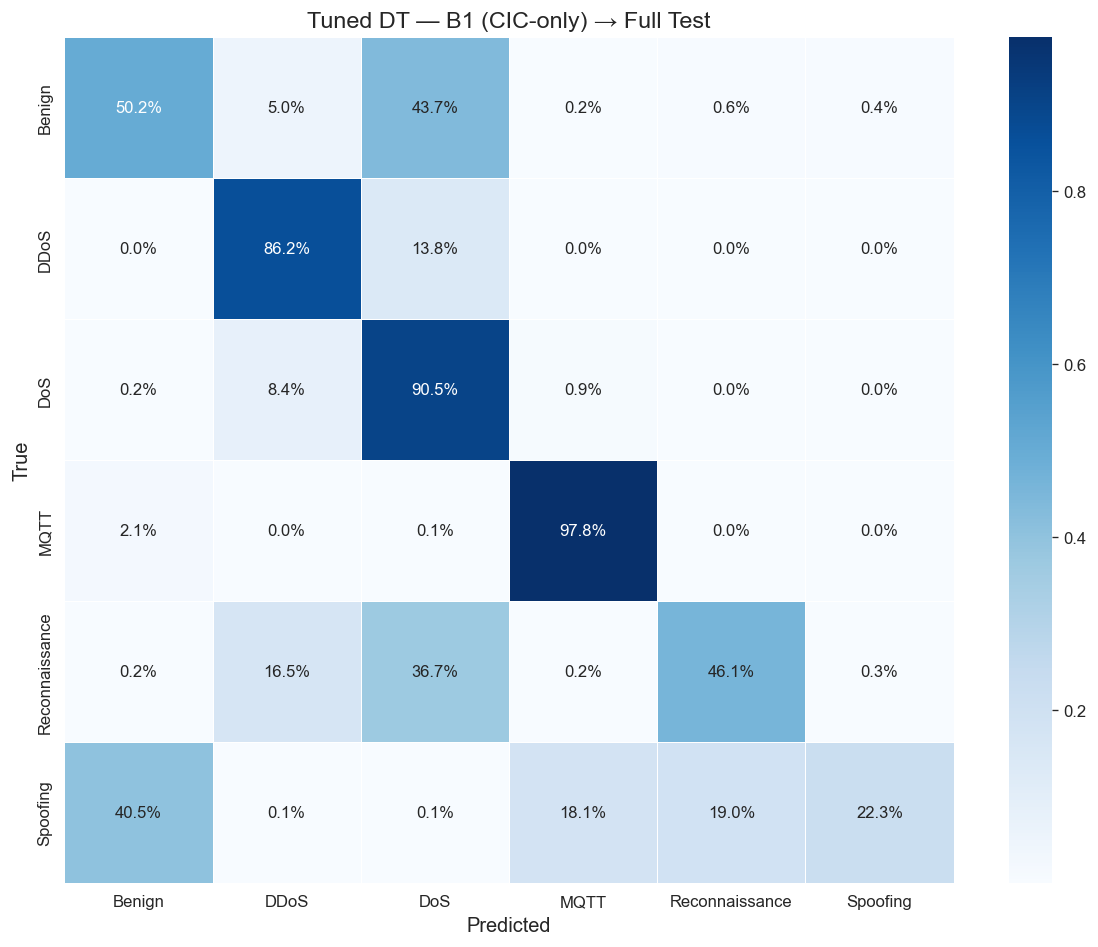

  Saved: /Users/pantelos/Documents/diploma_thesis/report/figures/ch5_dt_cm_b2_full.png


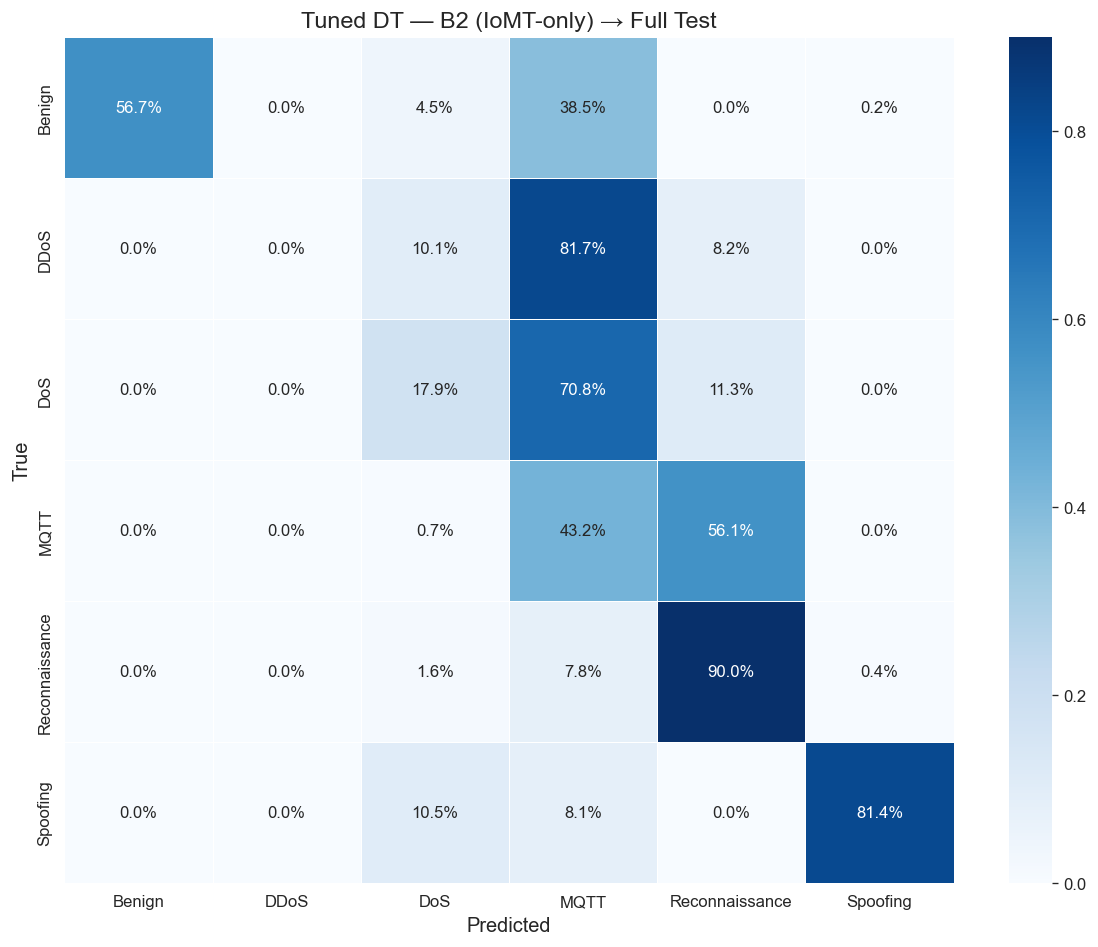

  Saved: /Users/pantelos/Documents/diploma_thesis/report/figures/ch5_dt_cm_u_full.png


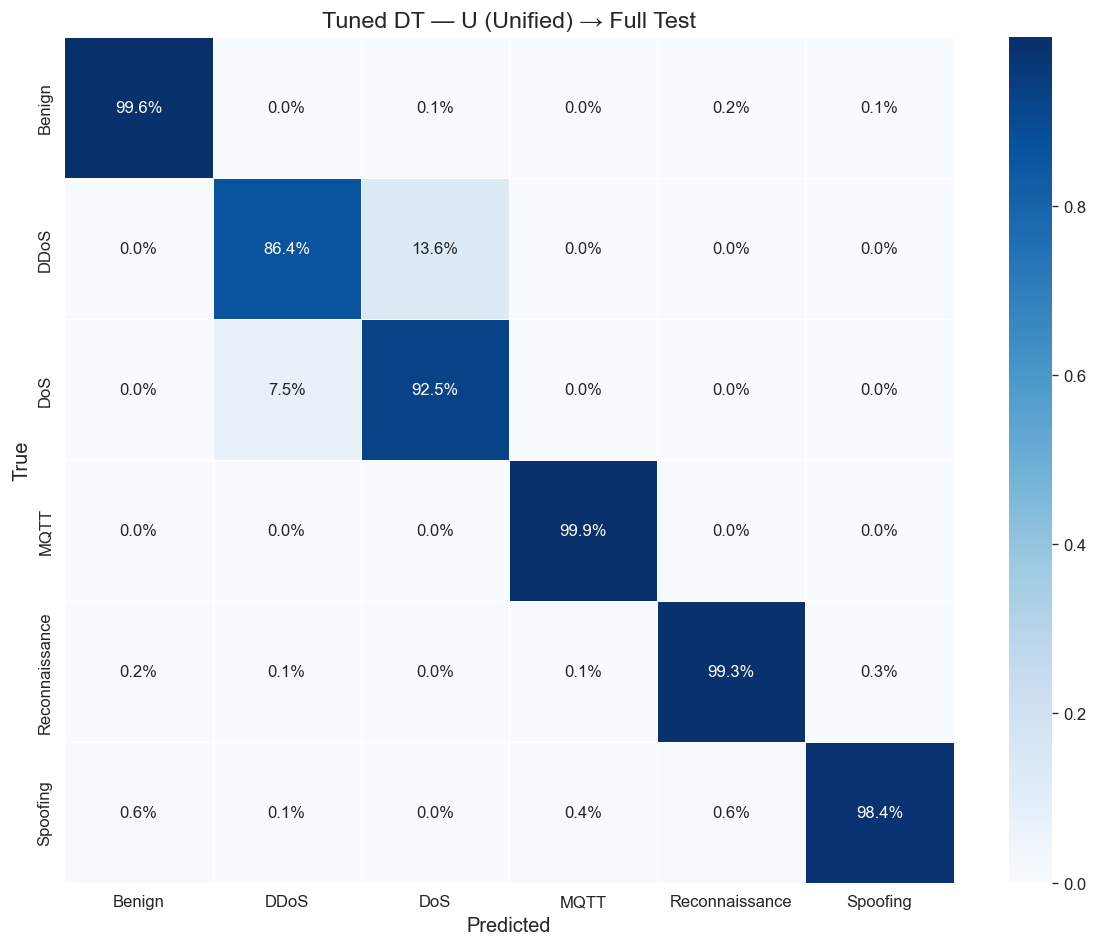

  Saved: /Users/pantelos/Documents/diploma_thesis/report/figures/ch5_dt_cm_b1_xd_iomt.png


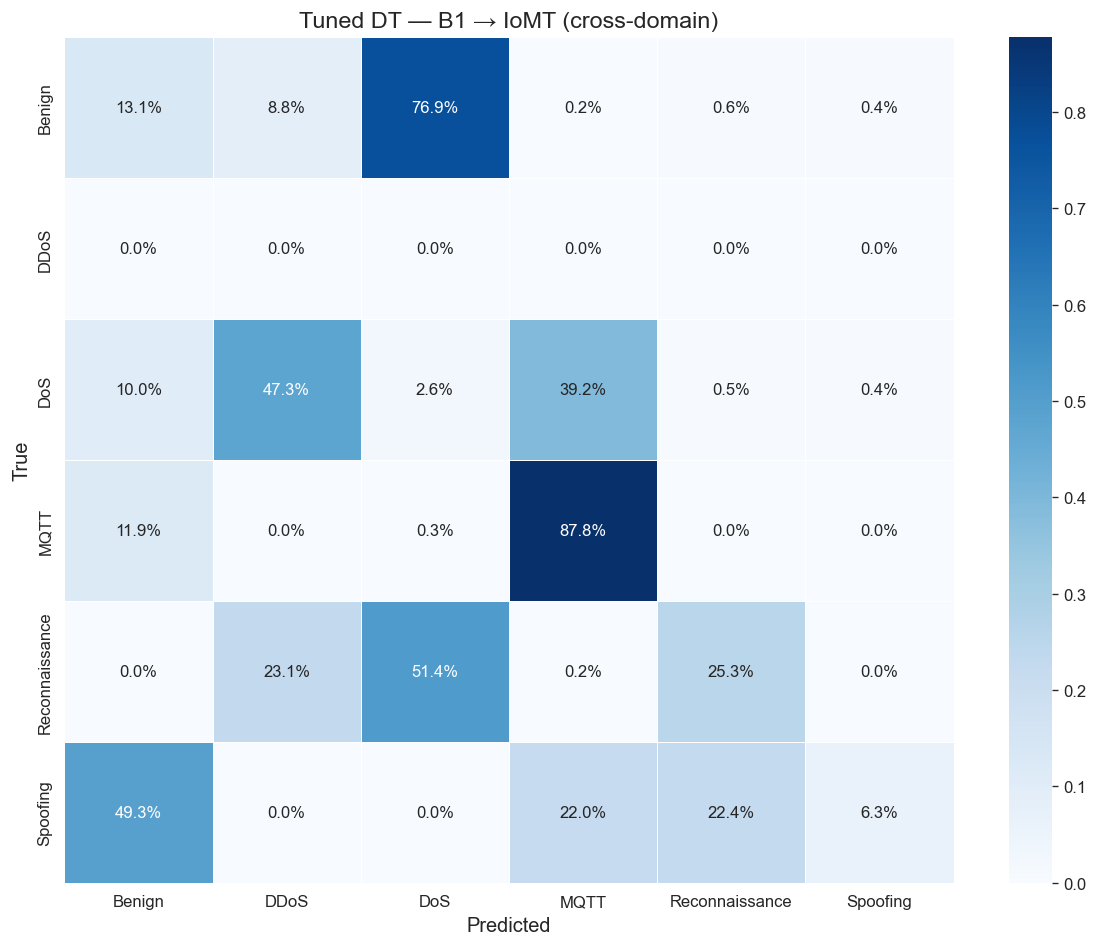

  Saved: /Users/pantelos/Documents/diploma_thesis/report/figures/ch5_dt_cm_b2_xd_iomt.png


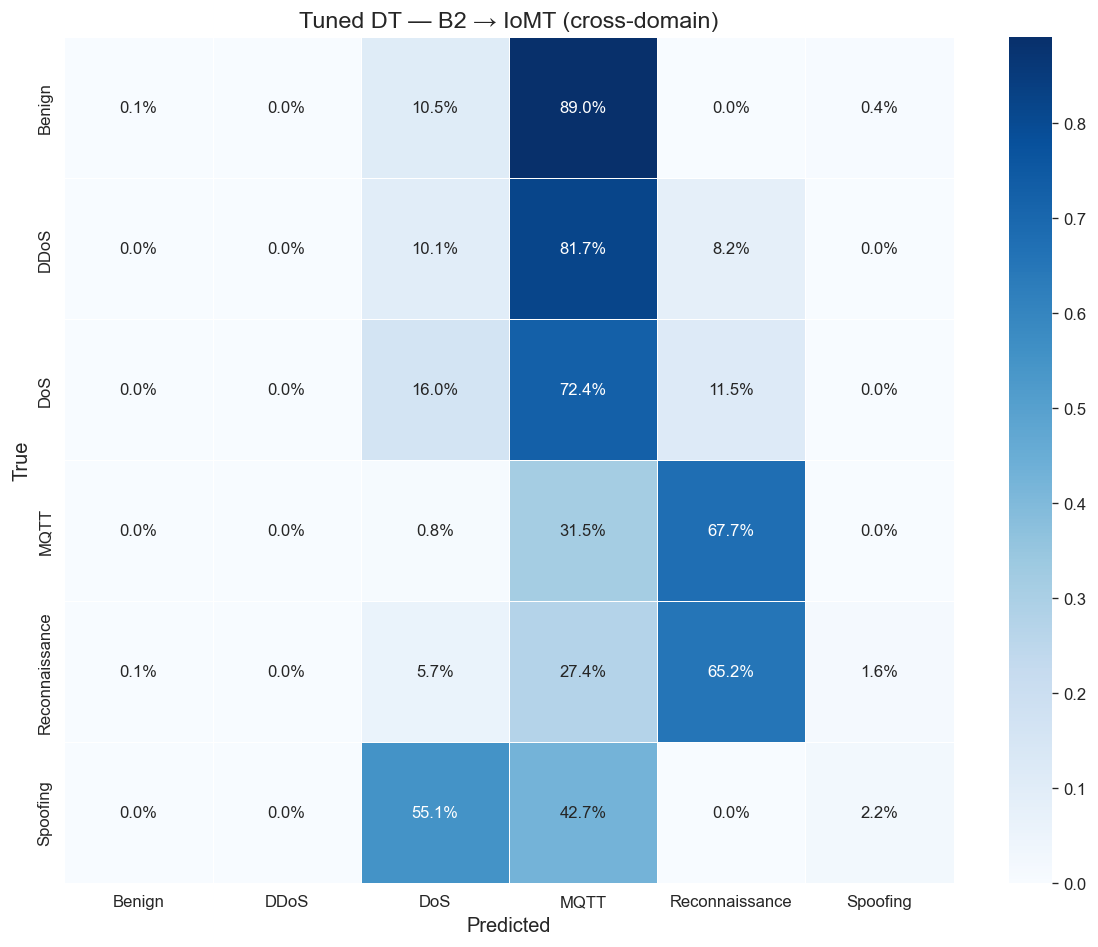

In [14]:
# --- Confusion Matrices (Tuned models, full test set) ---
for regime_key in ("B1", "B2", "U"):
    res_key = f"Tuned-{regime_key}"
    cm = tuned_xd_results[res_key]["full"]["cm"]
    fig = plot_confusion_matrix(
        cm, GLOBAL_CLASSES,
        title=f"Tuned DT — {regime_key} ({REGIME_LABEL[regime_key]}) → Full Test",
        save_path=str(FIGURES_DIR / f"ch5_dt_cm_{regime_key.lower()}_full.png"),
    )
    plt.show()
    plt.close(fig)

# Cross-domain confusion matrices (most informative for the thesis)
xd_pairs = [("B1", "IoMT-TrafficData", "IoMT"),
            ("B2", "CICIoMT2024", "CIC")]
for regime_key, other_src, tag in xd_pairs:
    res_key = f"Tuned-{regime_key}"
    if other_src in tuned_xd_results[res_key]:
        cm = tuned_xd_results[res_key][other_src]["cm"]
        fig = plot_confusion_matrix(
            cm, GLOBAL_CLASSES,
            title=f"Tuned DT — {regime_key} → {tag} (cross-domain)",
            save_path=str(FIGURES_DIR / f"ch5_dt_cm_{regime_key.lower()}_xd_{tag.lower()}.png"),
        )
        plt.show()
        plt.close(fig)

  Saved: /Users/pantelos/Documents/diploma_thesis/report/figures/ch5_dt_feature_importance_unified.png


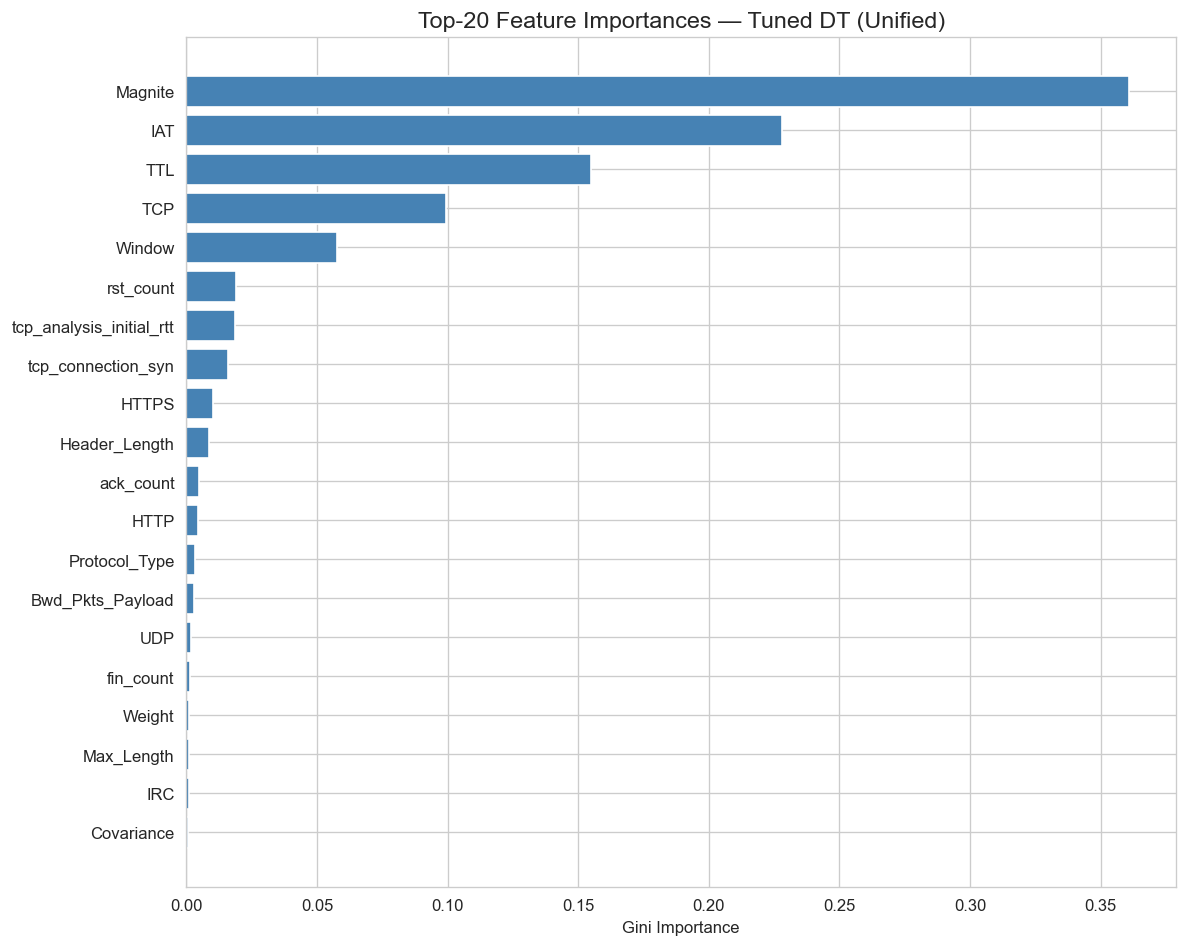

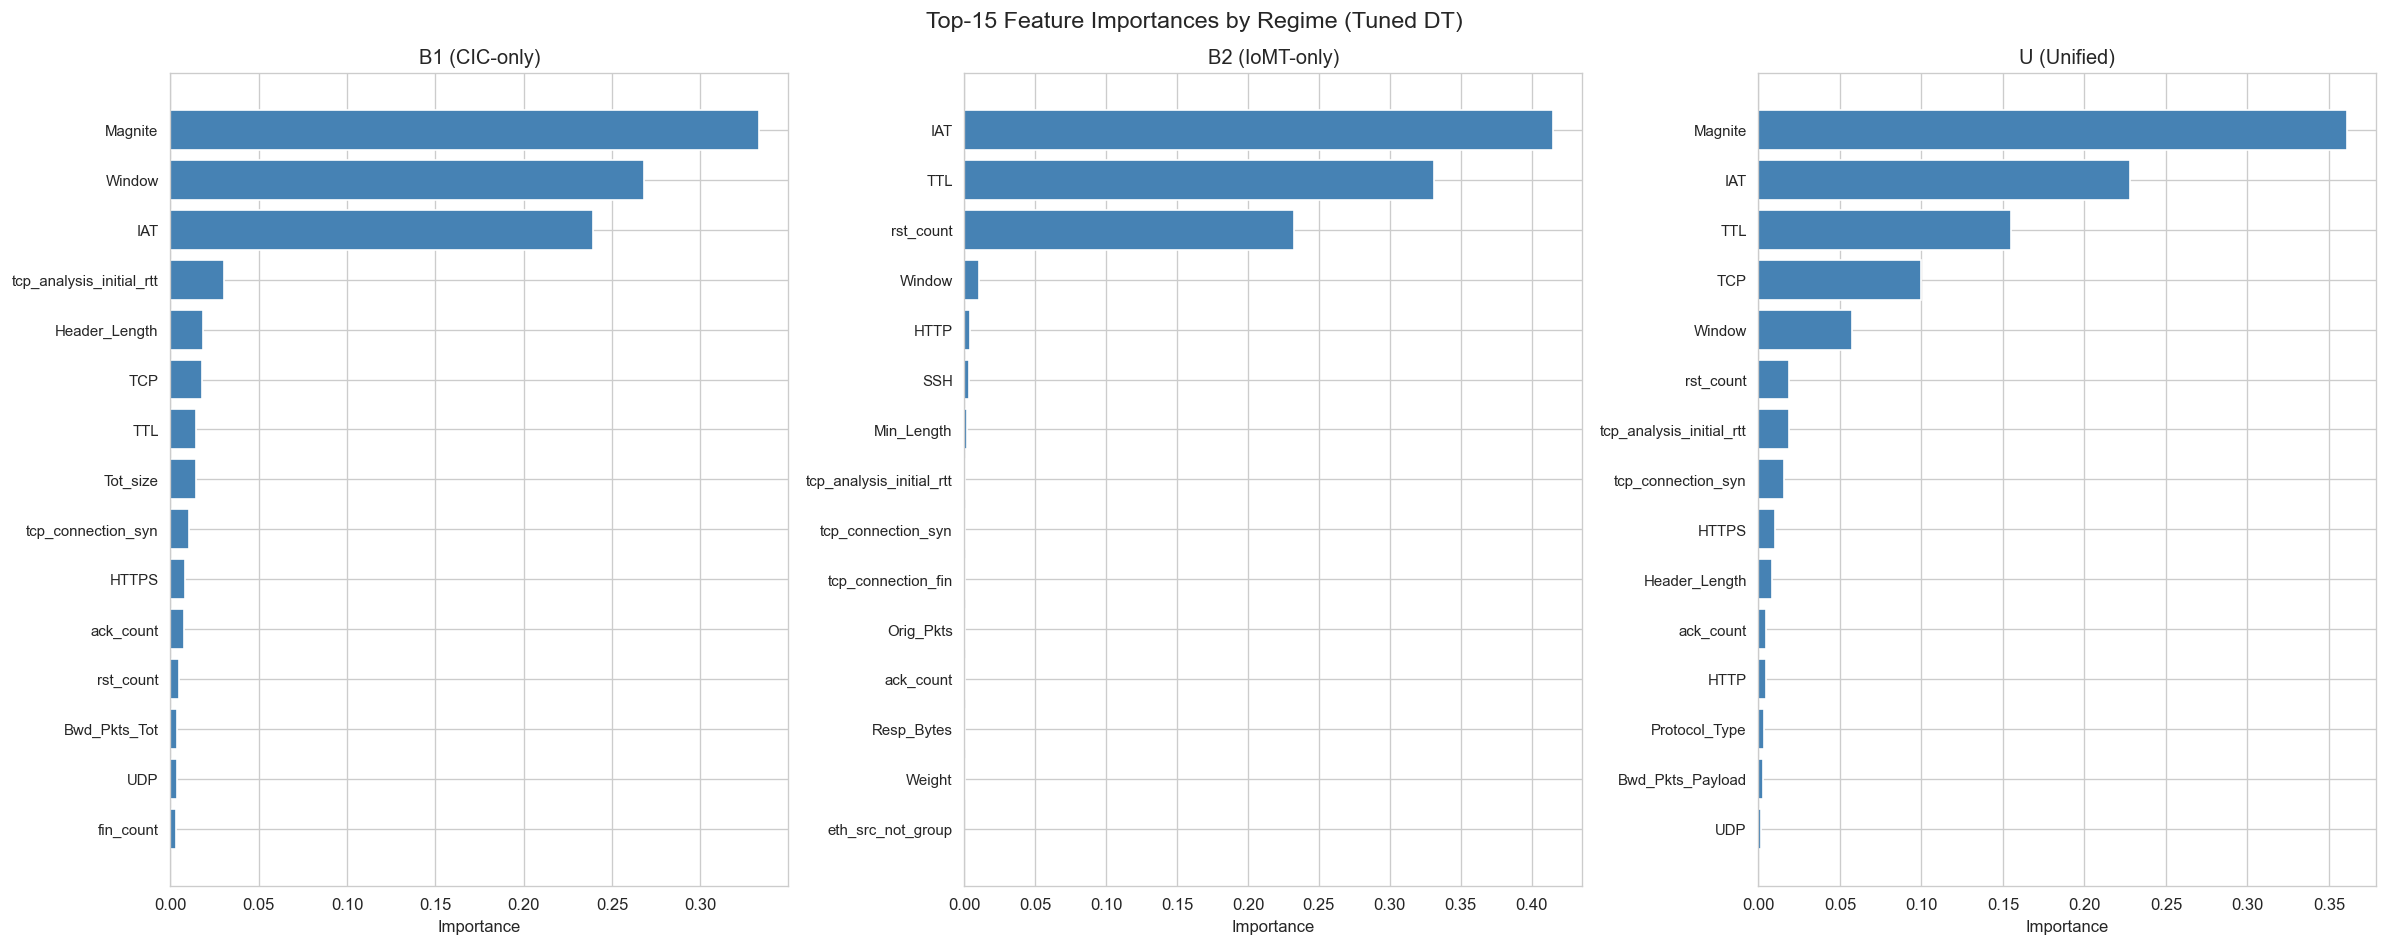

In [15]:
# --- Feature Importance (Tuned Unified model) ---
fig = plot_feature_importance(
    tuned_models["U"], feature_cols, top_n=20,
    title="Top-20 Feature Importances — Tuned DT (Unified)",
    save_path=str(FIGURES_DIR / "ch5_dt_feature_importance_unified.png"),
)
plt.show()
plt.close(fig)

# Comparison: B1 vs B2 vs U feature importance
fig, axes = plt.subplots(1, 3, figsize=(20, 8))
for ax, regime_key in zip(axes, ("B1", "B2", "U")):
    imp = tuned_models[regime_key].feature_importances_
    idx = np.argsort(imp)[::-1][:15]
    ax.barh(range(15), imp[idx[::-1]], align="center", color="steelblue")
    ax.set_yticks(range(15))
    ax.set_yticklabels([feature_cols[i] for i in idx[::-1]], fontsize=9)
    ax.set_xlabel("Importance")
    ax.set_title(f"{regime_key} ({REGIME_LABEL[regime_key]})")
plt.suptitle("Top-15 Feature Importances by Regime (Tuned DT)", fontsize=14)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "ch5_dt_feature_importance_comparison.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

  Saved: /Users/pantelos/Documents/diploma_thesis/report/figures/ch5_dt_regime_comparison_f1macro.png


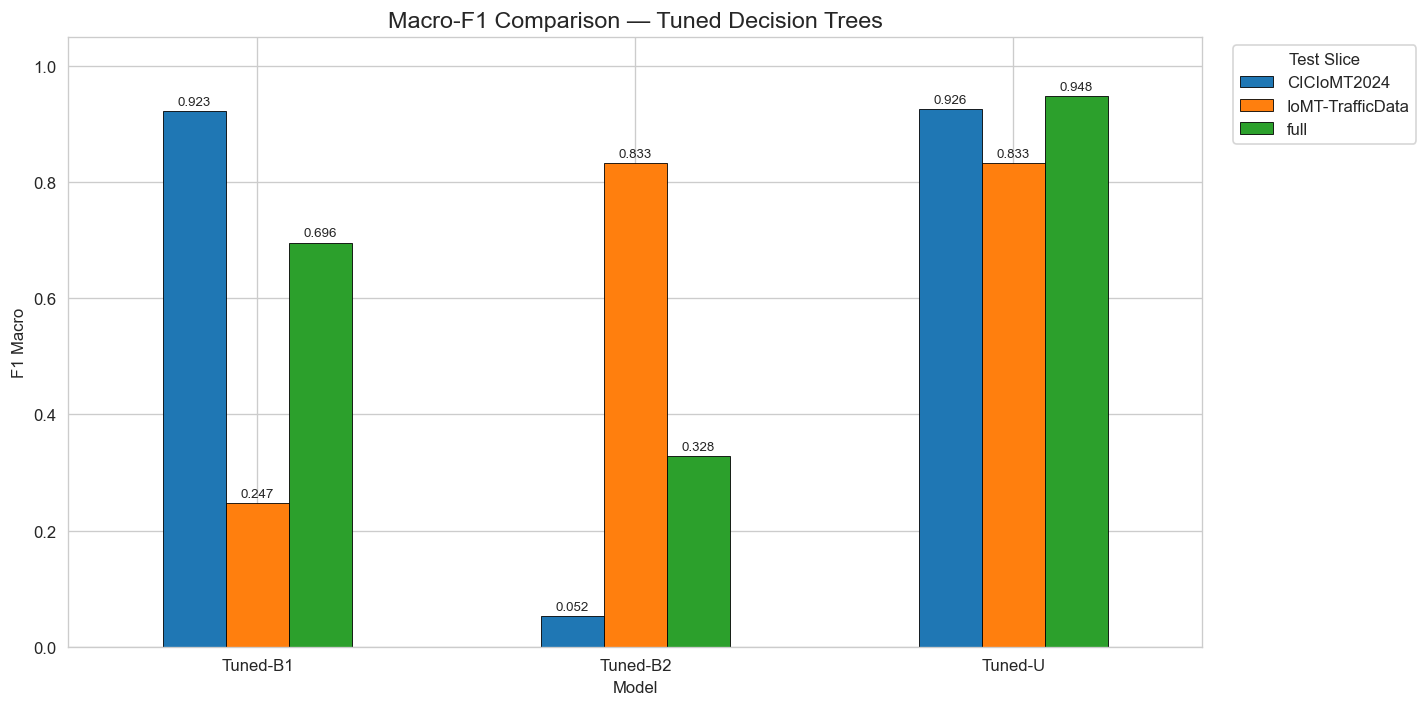

  Saved: /Users/pantelos/Documents/diploma_thesis/report/figures/ch5_dt_per_class_f1.png


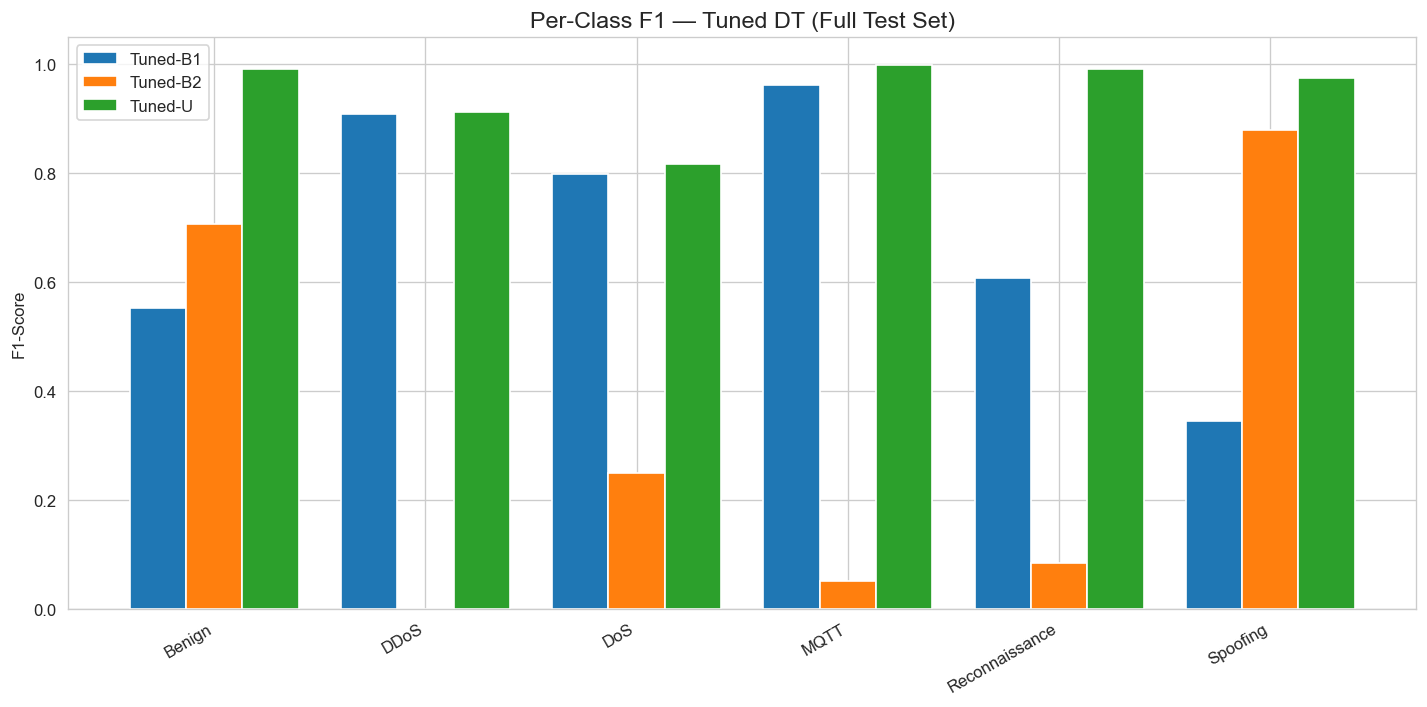

In [16]:
# --- Regime Comparison Bar Chart ---
fig = plot_regime_comparison(
    tuned_eval_df, metric="f1_macro",
    title="Macro-F1 Comparison — Tuned Decision Trees",
    save_path=str(FIGURES_DIR / "ch5_dt_regime_comparison_f1macro.png"),
)
plt.show()
plt.close(fig)

# --- Per-class F1 comparison ---
fig = plot_per_class_f1(
    tuned_xd_results, le, test_slice="full",
    title="Per-Class F1 — Tuned DT (Full Test Set)",
    save_path=str(FIGURES_DIR / "ch5_dt_per_class_f1.png"),
)
plt.show()
plt.close(fig)

## 9. Per-Class Analysis (Classification Reports)

Detailed per-class metrics for the tuned models on the full test set.

In [17]:
from sklearn.metrics import classification_report as cr_text

for regime_key in ("B1", "B2", "U"):
    res = tuned_xd_results[f"Tuned-{regime_key}"]["full"]
    y_true_full = le.transform(splits["test"]["label_category"])
    y_pred_full = res["y_pred"]
    print(f"\n{'='*60}")
    print(f"Classification Report — Tuned DT {regime_key} ({REGIME_LABEL[regime_key]}) → Full Test")
    print(f"{'='*60}")
    print(cr_text(
        y_true_full, y_pred_full,
        target_names=GLOBAL_CLASSES,
        zero_division=0,
    ))


Classification Report — Tuned DT B1 (CIC-only) → Full Test
                precision    recall  f1-score   support

        Benign       0.62      0.50      0.55      8018
          DDoS       0.96      0.86      0.91    805244
           DoS       0.71      0.91      0.80    322273
          MQTT       0.95      0.98      0.96     57891
Reconnaissance       0.90      0.46      0.61      6904
      Spoofing       0.75      0.22      0.34      1401

      accuracy                           0.87   1201731
     macro avg       0.81      0.66      0.70   1201731
  weighted avg       0.89      0.87      0.88   1201731


Classification Report — Tuned DT B2 (IoMT-only) → Full Test
                precision    recall  f1-score   support

        Benign       0.94      0.57      0.71      8018
          DDoS       0.00      0.00      0.00    805244
           DoS       0.41      0.18      0.25    322273
          MQTT       0.03      0.43      0.05     57891
Reconnaissance       0.04      0.90


Classification Report — Tuned DT B2 (IoMT-only) → Full Test
                precision    recall  f1-score   support

        Benign       0.94      0.57      0.71      8018
          DDoS       0.00      0.00      0.00    805244
           DoS       0.41      0.18      0.25    322273
          MQTT       0.03      0.43      0.05     57891
Reconnaissance       0.04      0.90      0.08      6904
      Spoofing       0.96      0.81      0.88      1401

      accuracy                           0.08   1201731
     macro avg       0.40      0.48      0.33   1201731
  weighted avg       0.12      0.08      0.08   1201731




Classification Report — Tuned DT U (Unified) → Full Test
                precision    recall  f1-score   support

        Benign       0.99      1.00      0.99      8018
          DDoS       0.97      0.86      0.91    805244
           DoS       0.73      0.93      0.82    322273
          MQTT       1.00      1.00      1.00     57891
Reconnaissance       0.99      0.99      0.99      6904
      Spoofing       0.97      0.98      0.98      1401

      accuracy                           0.89   1201731
     macro avg       0.94      0.96      0.95   1201731
  weighted avg       0.91      0.89      0.89   1201731



In [18]:
from IPython.display import display, Markdown


def _f1m(res_dict, slice_key):
    return res_dict[slice_key]["metrics"]["f1_macro"]


b1_full = _f1m(tuned_xd_results["Tuned-B1"], "full")
b1_xd = _f1m(tuned_xd_results["Tuned-B1"], "IoMT-TrafficData")
b2_full = _f1m(tuned_xd_results["Tuned-B2"], "full")
b2_xd = _f1m(tuned_xd_results["Tuned-B2"], "CICIoMT2024")
u_full = _f1m(tuned_xd_results["Tuned-U"], "full")
u_per_src = 0.5 * (
    _f1m(tuned_xd_results["Tuned-U"], "CICIoMT2024")
    + _f1m(tuned_xd_results["Tuned-U"], "IoMT-TrafficData")
)

summary_md = f"""## 10. Summary

**Key findings** (tuned DT, test set):

| Metric | B1 (CIC-only) | B2 (IoMT-only) | U (Unified) |
|--------|---------------|----------------|-------------|
| Macro-F1 (full test) | {b1_full:.4f} | {b2_full:.4f} | {u_full:.4f} |
| F1-macro cross-domain* | {b1_xd:.4f} | {b2_xd:.4f} | {u_per_src:.4f} |

*Cross-domain: B1 evaluated on IoMT test slice only; B2 on CIC test slice only; U shows the **mean** of macro-F1 on the CIC and IoMT test slices (both seen in training).

**Next steps**: Random Forest, XGBoost, McNemar's test for pairwise comparison.
"""
display(Markdown(summary_md))

## 10. Summary

**Key findings** (tuned DT, test set):

| Metric | B1 (CIC-only) | B2 (IoMT-only) | U (Unified) |
|--------|---------------|----------------|-------------|
| Macro-F1 (full test) | 0.6959 | 0.3284 | 0.9480 |
| F1-macro cross-domain* | 0.2474 | 0.0523 | 0.8794 |

*Cross-domain: B1 evaluated on IoMT test slice only; B2 on CIC test slice only; U shows the **mean** of macro-F1 on the CIC and IoMT test slices (both seen in training).

**Next steps**: Random Forest, XGBoost, McNemar's test for pairwise comparison.
